# Jaccard Analysis
### N Value Sweep Analysis & Decision Rule

This notebook provides an analysis of phylogenetically informed dimensionality reduction on the URIEL+ dataset ($8,128$ languages $\times$ $593$ features). It shows the phylogenetic weighting variants, establishes the decision rule using a pre-decided range for Jaccard distance, and analyzes results across N features selected ($N = 100$ to $400$).

## 1. Phylogenetic Weighting Variants

Standard PCA treats every language observation equally, which introduces genealogical bias through the overrepresentation of well documented language families. To correct this, weighted SVD is applied using the phylogenetic weighting.

* **`uniform`**: The unweighted baseline treating all languages with equal probability. Used as the standard.
* **`w_finest`**: Computes weights based on the finest grained Glottolog taxonomic classification. This captures the lowest tier family structure.
* **`w_level3_a1` & `w_level3_a05`**: Hierarchical family level smoothing variants using smoothing parameters ($\alpha = 1.0$ and $\alpha = 0.5$). This captures middle level family structure.
* **`w_finest_adminmedian` & `w_finest_adminzero`**: Variants for handling unclassified, isolate, or administrative language groupings respectively using median weighting and  zero weighting imputation strategies.

## 2. The Decision Rule

To find the optimal number of features ($N$) and validate that phylogenetic weighting achieves its intended purpose without introducing noise, we established a pre-defined Jaccard distance ($d_J$) range for the distance of the variants (v) at each $N$ size:

$$
0.15 \le d_J\left(S_{\text{standard}}^{(N)},\; S_{\text{weighted}}^{(N, v)}\right) \le 0.40
$$

### Rationale for the Bounds:
* **Lower Bound ($0.15$):** Ensures that phylogenetic weighting gives a meaningful change in the selected feature set. If $d_J$ < 0.15, the weighting will have little impact on the performance in down stream tasks.
* **Upper Bound ($0.40$):** Stops the introduction of instability, and noise. If $d_J > 0.40$, feature selection could change too much, loosing the core structure of the feature set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load master sweep summary
df = pd.read_csv('master_sweep_summary.csv')
print(df.to_string())

      N        weight_variant  overlap_with_standard  jaccard_similarity  jaccard_distance  added  removed  n_components  explained_variance
0   100               uniform                    100              1.0000            0.0000      0        0           215            0.950116
1   100              w_finest                     63              0.4599            0.5401     37       37           215            0.950362
2   100           w_level3_a1                     55              0.3793            0.6207     45       45           202            0.950491
3   100          w_level3_a05                     56              0.3889            0.6111     44       44           213            0.950081
4   100  w_finest_adminmedian                     58              0.4085            0.5915     42       42           215            0.950011
5   100    w_finest_adminzero                     57              0.3986            0.6014     43       43           216            0.950270
6   150      

## 3. Results Analysis

Visualization of the Jaccard distance ($d_J$) across different feature selection sizes ($N$) for each phylogenetic weighting variant, to see which $N$ value satisfies the defined decision rule.

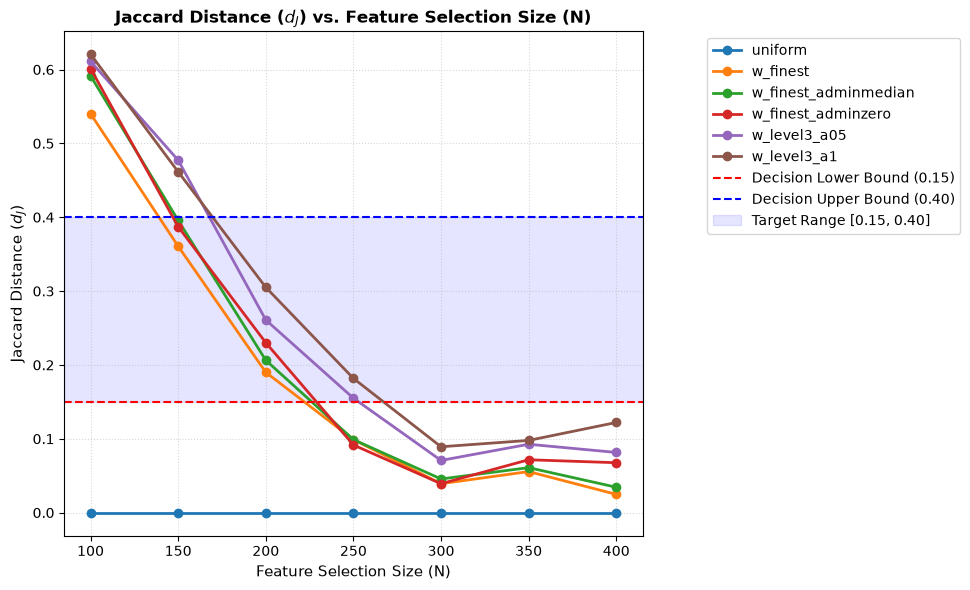

In [15]:
plt.figure(figsize=(10, 6))

for variant, group in df.groupby('weight_variant'):
    plt.plot(group['N'], group['jaccard_distance'], marker='o', linewidth=2, label=variant)

plt.axhline(0.15, color='red', linestyle='--', label='Decision Lower Bound (0.15)')
plt.axhline(0.40, color='blue', linestyle='--', label='Decision Upper Bound (0.40)')
plt.axhspan(0.15, 0.40, color='blue', alpha=0.1, label='Target Range [0.15, 0.40]')

plt.title('Jaccard Distance ($d_J$) vs. Feature Selection Size (N)', fontsize=12, fontweight='bold')
plt.xlabel('Feature Selection Size (N)', fontsize=11)
plt.ylabel('Jaccard Distance ($d_J$)', fontsize=11)
plt.legend(bbox_to_anchor=(1.1, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Conclusion & Selected N Value

Based on our decision rule:
1. **$N \le 100$** is rejected ($d_J > 0.40$, excessive instability).
2. **$N \ge 250$** is rejected ($d_J < 0.15$, insufficient structural change).
3. **$N = 200$** emerges as the optimum, where phylogenetic variants land within the pre-defined range of Jaccard Distance ($d_J$).

We will proceed with **$N = 200$** for our final LangRank evaluation.